*Template notebook generated on 2026-10-29 22:14:28*

In [1]:
import os, sys; sys.path.insert(0, os.path.join(os.path.dirname(globals().get('__vsc_ipynb_file__', '')) or os.getcwd(), 'Files'))
from pset_check import check_answer

In [2]:
# Enter the email address associated with your Gradescope account.
my_email = "jhgunton@mit.edu"

# 20.320 Collaborative Modeling Project

## Antibody-drug conjugate trafficking and pharmacokinetic model

**Milestone 1 due:** November 12, 2026, at 11:59 pm.

**Milestone 2 due:** November 24, 2026, at 11:59 pm.

### Background

Antibody-drug conjugates (ADCs) are a class of biologic drugs that have expanded
effective treatment options for patients with cancer. There are 16 ADCs that are
currently FDA-approved for use in the US to treat multiple types of human cancers,
and many more in preclinical and clinical development.

### Objective

Imagine you are a scientist at a biotech or pharma company that is working to
develop ADCs. Your goal is to develop a quantitative model predicting ADC
trafficking and efficacy and use it to understand what makes a safe and effective ADC.

### Project overview

Working with your teammates, generate a model
of ADC trafficking and efficacy (cancer cell killing) using the blockbuster
anti-HER2 ADC **Enhertu** as the basis for your model. The lectures on receptor
trafficking, cell growth and death, and pharmacokinetics will be especially useful
as you build your model, as will the coding notebooks from PSETs 4, 5, and 6.

The project has three parts:

1. **Milestone 1: Base model and dosing analysis.** Diagram and implement the
   system described below, establish its untreated baseline, use the model to
   choose a dose, and explore how the spacing between doses affects the outcome.
2. **Milestone 2: Model modification.** Change an aspect of the ADC system to
   improve efficacy or safety, and analyze the effect.
3. **Final project report.** Bring the base-model analysis and the modification
   together in a written report.

## The system

Your Milestone 1 model should represent the system described below.

The targeted HER2 receptor is synthesized as a surface monomer and exists as both
a monomer and a dimer on cancer cells. HER2 monomer dimerizes reversibly with
association rate constant $k_{\mathrm{on,HER2}}$ and dissociation rate constant
$k_{\mathrm{off,HER2}}$. The Enhertu ADC binds only surface HER2 monomer, with
apparent association and dissociation rate constants $k_{\mathrm{on,ADC}}$ and
$k_{\mathrm{off,ADC}}$. These apparent rate constants describe the observed binding
kinetics of the bivalent antibody to HER2 receptors on cancer cells, without
modeling its two binding arms separately. Free monomer internalizes with
rate constant $k_{er}$, and dimers internalize with rate constant $k_{ec}$. You may
assume that ADC binding does not change the internalization rate of a monomer.

Once internalized, you may assume that the ADC rapidly unbinds from HER2 in the
low-pH environment of the endosome. Internal HER2 monomers and dimers either
recycle to the surface or degrade, with rate constants $k_{\mathrm{rec}}$ and
$k_{\mathrm{deg,HER2}}$. Dimers recycle intact. The unbound ADC stays inside the cell.

Each Enhertu antibody carries eight molecules of the cytotoxic drug deruxtecan,
the ADC's *payload*. For simplicity, model their release from the internalized
ADC as a single first-order step with rate constant $k_{\mathrm{rel,i}}$.
Released endosomal payload either escapes to the cytoplasm or degrades, with rate
constants $k_{\mathrm{esc}}$ and $k_{\mathrm{deg,P}}$. Payload that escapes
accumulates in the cytoplasm, where it also degrades with rate constant
$k_{\mathrm{deg,P}}$. The payload must be released and
must escape the endosome before it can act. Only cytoplasmic payload kills cancer cells.
The killing rate constant is a Monod function of the payload's **cytoplasmic
concentration**. Its maximum value and the concentration that gives half the
maximum are given below. Cancer cells grow with a 14-day
doubling time.

Payload released in circulation, before the ADC reaches cancer cells, is one
source of the side effects patients experience. Because the payload is more toxic
than standard chemotherapy, even low blood concentrations can cause harm, so you
will track the payload concentration in blood alongside tumor killing. Each IV
dose adds loaded ADC (ADC still carrying its payload) to blood. Loaded ADC in
blood is removed by background intact-ADC clearance, by tumor binding, and by circulating payload release with
rate constant $k_{\mathrm{rel,b}}$. As in the endosome, model this release as a
single first-order step that frees all eight payload molecules. Released blood
payload clears with rate constant $k_{\mathrm{clear}}$.

### Modeling assumptions

* Blood is well mixed, and every living cancer cell has the same per-cell state.
* The model treats the initial tumor as made up entirely of cancer cells, with no
  space between them.
* Cell-associated species are tracked in molecules per living cell, and blood
  species in molar concentration. The total number of living cells determines
  how much ADC the tumor binds and takes up from blood.
* Concentrations inside the cell, including the cytoplasmic payload concentration
  that drives killing, are calculated using the whole-cell volume.
* Cell division leaves the average receptor and drug amounts per living cell
  unchanged, and death removes the contents of dying cells.
* Each IV dose is an instantaneous addition of loaded ADC to blood.
* The model ignores the bare antibody left after an ADC releases its payload, even
  though in reality it could still bind HER2 and compete with loaded ADC.
* Released blood payload does not enter tumor cells.

### Model parameters

#### Patient, tumor, and drug properties

| Quantity | Value |
| --- | --- |
| Blood volume | 5 L |
| Patient mass | 70 kg |
| Initial tumor | Sphere, 1 cm diameter |
| Cancer cell | Sphere, 10 μm diameter |
| ADC molecular weight | 156,000 g/mol |
| Payload molecular weight used for reporting | 1000 g/mol, a model assumption |
| Drug-to-antibody ratio | 8 payload molecules per loaded ADC |

#### Kinetic parameters

Use **minutes** for simulation time. Convert reported seconds and days consistently.
The molar HER2 association rate constant must also be converted for per-cell species.

| Parameter | Python name | Given value |
| --- | --- | --- |
| HER2 synthesis | <tt>q_HER2</tt> | 1000 molecules/cell/min |
| HER2 dimer association | <tt>k_on_HER2</tt> | $10^5$ M$^{-1}$ s$^{-1}$ |
| HER2 dimer dissociation | <tt>k_off_HER2</tt> | $3\times10^{-4}$ s$^{-1}$ |
| ADC association to surface monomer | <tt>k_on_ADC</tt> | $6\times10^5$ M$^{-1}$ s$^{-1}$ |
| ADC dissociation | <tt>k_off_ADC</tt> | $3\times10^{-4}$ s$^{-1}$ |
| Monomer and ADC-monomer internalization | <tt>k_er</tt> | 0.003 min$^{-1}$ |
| Dimer internalization | <tt>k_ec</tt> | 0.01 min$^{-1}$ |
| HER2 monomer and intact-dimer recycling | <tt>k_rec</tt> | 0.03 min$^{-1}$ |
| Endosomal HER2 degradation | <tt>k_deg_HER2</tt> | 0.003 min$^{-1}$ |
| Endosomal payload release | <tt>k_rel_i</tt> | 0.06 min$^{-1}$ |
| Circulating payload release | <tt>k_rel_b</tt> | $6.68\times10^{-7}$ min$^{-1}$ (from plasma stability: 2% released in 21 days) |
| Background loaded-ADC clearance | <tt>k_clear_ADC</tt> | 5.7-day half-life |
| Endosomal payload escape | <tt>k_esc</tt> | 0.03 min$^{-1}$ |
| Payload degradation in endosome and cytoplasm | <tt>k_deg_P</tt> | 0.003 min$^{-1}$ |
| Blood payload clearance | <tt>k_clear</tt> | 1 day$^{-1}$ |
| Cancer-cell growth | <tt>mu</tt> | 14-day doubling time |
| Maximum killing rate constant | <tt>delta_max</tt> | 0.15 day$^{-1}$ |
| Cytoplasmic concentration for half-maximal killing | <tt>K_P</tt> | 10 μM |

The maximum killing rate constant is a value chosen for this model, not one fitted
to clinical data, so the selected dose should not be compared directly with
clinical dosing.

### Measuring blood payload exposure

To compare how much free payload the rest of the body is exposed to, use two
measures of the blood payload concentration $[P_b](t)$:

* **Peak concentration:** the highest value of $[P_b]$ during treatment. It
  measures the most intense exposure at any one time.
* **Area under the curve (AUC):** the integral
  $\int_0^{63\,\mathrm{days}} [P_b]\,dt$, in units of concentration × time. It
  measures cumulative exposure. (So, for example, a persistent low concentration can give the
  same AUC as a high concentration that clears quickly.)

The AUC will be calculated by an *accumulator*. This is an extra variable that simply integrates
$[P_b]$ as the simulation runs without affecting the model. The accumulator's final value is the
AUC. Instructions for adding an accumulator appear in a question below.

These measures let you compare regimens and ADC designs with one another. Payload
released in circulation is only one contributor to toxicity, so these measures are imperfect
predictors of patient safety.

## Milestone 1: Base model and dosing analysis

For Milestone 1, you will implement the base model, establish its untreated baseline,
and use the model to find the smallest dose that leaves no more than 5% of the
initial cancer cells after 63 days, while tracking the payload exposure in blood.
You will then use the model explorer to see how the spacing between doses affects
the outcome.

In [3]:
import os, sys; sys.path.insert(0, os.path.join(os.path.dirname(globals().get('__vsc_ipynb_file__', '')) or os.getcwd(), 'Files'))
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

sys.path.insert(0, os.path.dirname(globals().get('__vsc_ipynb_file__', '')) or os.getcwd())
from modelingTools import (
    AVOGADRO, KineticModel, Compartment, Parameters, Reaction, Impulse, Unit,
    Simulation, plot_simulations,
)
from design_project_helpers import build_model

minutes_per_day = 1440
dose_days = [0.0, 21.0, 42.0]
assessment_day = 63.0
maximum_dose_mg_per_kg = 4.5
target_fraction_remaining = 0.05

_instructor_source = False

from answer_helpers import add_answer
from design_project_helpers import show_dosing_demo

<style class="question-heading-css">
h2.question-heading, h3.question-heading,
h2:has(> .question-heading-marker), h3:has(> .question-heading-marker) {
  color: #7030A0;
  font-weight: bold;
  margin: 0;
  page-break-after: avoid;
  break-after: avoid;
}
h2.question-heading, h2:has(> .question-heading-marker) {
  font-size: 1.5em;
  text-align: center;
}
h3.question-heading, h3:has(> .question-heading-marker) {
  font-size: 1.1em;
}
.question-heading .question-heading-points,
h2:has(> .question-heading-marker) .question-heading-points,
h3:has(> .question-heading-marker) .question-heading-points {
  font-weight: normal;
}
</style>

## <span class="question-heading-marker" data-kind="standalone" data-number="1"></span>Problem 1. Draw the system before coding <span class="question-heading-points">(10 pts — manual)</span>

Draw a diagram of the complete base model. Distinguish blood, the cell surface,
endosomes, and cytoplasm. Label species, transfers, sources, and losses with
consistent symbols and rate constants. Show how cytoplasmic payload influences
living cancer-cell number and where doses enter.

Use this diagram to organize your implementation. A hand-drawn diagram is fine.

In [4]:
# Run this cell to add your answer (ordered text and image pages, with math/equations).
add_answer("milestone1_system_diagram")

<style class="question-heading-css">
h2.question-heading, h3.question-heading,
h2:has(> .question-heading-marker), h3:has(> .question-heading-marker) {
  color: #7030A0;
  font-weight: bold;
  margin: 0;
  page-break-after: avoid;
  break-after: avoid;
}
h2.question-heading, h2:has(> .question-heading-marker) {
  font-size: 1.5em;
  text-align: center;
}
h3.question-heading, h3:has(> .question-heading-marker) {
  font-size: 1.1em;
}
.question-heading .question-heading-points,
h2:has(> .question-heading-marker) .question-heading-points,
h3:has(> .question-heading-marker) .question-heading-points {
  font-weight: normal;
}
</style>

## <span class="question-heading-marker" data-kind="problem" data-number="2"></span>Problem 2. Build the system model

<style class="question-heading-css">
h2.question-heading, h3.question-heading,
h2:has(> .question-heading-marker), h3:has(> .question-heading-marker) {
  color: #7030A0;
  font-weight: bold;
  margin: 0;
  page-break-after: avoid;
  break-after: avoid;
}
h2.question-heading, h2:has(> .question-heading-marker) {
  font-size: 1.5em;
  text-align: center;
}
h3.question-heading, h3:has(> .question-heading-marker) {
  font-size: 1.1em;
}
.question-heading .question-heading-points,
h2:has(> .question-heading-marker) .question-heading-points,
h3:has(> .question-heading-marker) .question-heading-points {
  font-weight: normal;
}
</style>

### <span class="question-heading-marker" data-kind="subpart" data-number="2.1"></span>2.1 Implement the base model <span class="question-heading-points">(25 pts — autograded)</span>

Implement the system model using the provided library functions. Include every
process in the system, including cell growth, but leave out cell killing, which you
will add in the next part.


The [modeling library guide](Files/modelingTools/documentation.html) and its
[PDF](Files/modelingTools/documentation.pdf) describe the functions used here. <tt>help(Reaction)</tt>
and <tt>help(Simulation)</tt> also work inside the notebook.

Create the <tt>blood</tt> compartment with its volume, for example
<tt>Compartment('blood', volume=blood_volume_L)</tt>. Create the <tt>cell</tt> compartment with
its count variable set to <tt>N</tt> and its volume set to one cell's volume in liters:

```python
network.add_compartment(Compartment(
    'cell', count_variable='N', count_units='cells', volume_per_unit=cell_volume_L
))
```

Define <tt>blood_volume_L</tt> and <tt>cell_volume_L</tt> from the blood volume and cancer
cell diameter in the parameter tables. The cell volume lets <tt>s.molar(...)</tt> convert molecules per cell to M, which you will
need for cell killing.

Adding this compartment creates the count state <tt>N</tt>; do not add it again
with <tt>add_species</tt>. Declare the molecular species using the names below:

| State variable | Meaning | Compartment | Declared units |
| --- | --- | --- | --- |
| <tt>A_b</tt>, <tt>P_b</tt> | Loaded ADC and free payload in blood | <tt>blood</tt> | M |
| <tt>M_s</tt>, <tt>D_s</tt>, <tt>C_s</tt> | Surface monomer, dimer, and ADC-monomer complex | <tt>cell</tt> | #/cell |
| <tt>M_i</tt>, <tt>D_i</tt>, <tt>A_i</tt> | Internal monomer, dimer, and loaded ADC | <tt>cell</tt> | #/cell |
| <tt>P_i</tt>, <tt>P_c</tt> | Endosomal and cytoplasmic free payload | <tt>cell</tt> | #/cell |
| <tt>N</tt> | Living cancer cells | count of <tt>cell</tt> | cells |

Surface, endosomal, and cytoplasmic species all belong to the <tt>cell</tt> compartment.
To track where a molecule is within the cell, the model uses a separate species for each
location, such as <tt>M_s</tt> for surface monomer and <tt>M_i</tt> for internal monomer.

Represent exponential growth of <tt>N</tt> with this syntax:

```python
network.add_reaction(Reaction(
    'Cell growth', 'N', '2 N', forward_rate_constant='mu'
))
```

For a reaction between two per-cell species, such as HER2 dimerization, convert
the molar association rate constant to per-cell units. For binding between a blood
species in M and a receptor in #/cell, keep the association rate constant in
$\mathrm{M}^{-1}\,\mathrm{min}^{-1}$. The binding rate
$k_{\mathrm{on,ADC}}[A_b][M_s]$ is then in molecules per cell per minute.

Call the supplied <tt>build_model</tt> function to turn your network and parameters into
a runnable model, then inspect its equations with <tt>model.print_rate_equations()</tt>.

In [5]:
# Keep these three names. The automatic answer checks and later parts use them.
network = KineticModel()
parameters = Parameters()
from modelingTools import convert_rate_constant

# adding the blood and cell compartments.
blood_volume_L = 5.0
cell_radius_um = 10.0 / 2.0
cell_volume_L = 4.0 / 3.0 * np.pi * cell_radius_um**3 * 1e-15  # find cell volume approximating cell as sphere, then convert um^3 to L

network.add_compartment(Compartment('blood', volume= blood_volume_L))
network.add_compartment(Compartment('cell', count_variable = 'N', count_units='cells', volume_per_unit=cell_volume_L))

# declares the molecular species in the table, one call per species.
network.add_species('A_b', 'Loaded ADC in blood', 'M', 'blood')
network.add_species('P_b', 'Free payload in blood', 'M', 'blood')

network.add_species('M_s', 'Surface monomer', '#/cell', 'cell')
network.add_species('D_s', 'Surface dimer', '#/cell', 'cell')
network.add_species('C_s', 'Surface ADC-monomer complex', '#/cell', 'cell')

network.add_species('M_i', 'Internal monomer', '#/cell', 'cell')
network.add_species('D_i', 'Internal dimer', '#/cell', 'cell')
network.add_species('A_i', 'Internal loaded ADC', '#/cell', 'cell')

network.add_species('P_i', 'Endosomal free payload', '#/cell', 'cell')
network.add_species('P_c', 'Cytoplasmic free payload', '#/cell', 'cell')

# adds reactions to network, and your parameters to parameters.
# You may add cells if that makes your work easier to organize.
minutes_per_day = 24 * 60 # useful conversion so that all rate constants are in written with time units of minutes

# HER2 monomer synthesis
parameters.add('q_HER2', 1000, '#/cell/min', 'HER2 monomer synthesis')
k_on_HER2_per_cell = convert_rate_constant(
    1e5 * 60, # k_on value in M^-1 s^-1
    'M^-1 min^-1',
    '(#/cell)^-1 min^-1',
    volume=cell_volume_L
)
network.add_reaction(Reaction(
    'HER2 monomer synthesis',
    {},
    'M_s',
    forward_rate_constant='q_HER2'
))

# 2 M_s <-> D_s
parameters.add('k_on_HER2', k_on_HER2_per_cell, '(#/cell)^-1 min^-1', 'HER2 dimer association rate')
parameters.add('k_off_HER2', 3e-4 * 60, 'min^-1', 'HER2 dimer dissociation')
network.add_reaction(Reaction(
    'HER2 dimerization',
    '2 M_s',
    'D_s',
    forward_rate_constant='k_on_HER2',
    reverse_rate_constant='k_off_HER2'
))

# M_s + A_b <-> C_s
parameters.add('k_on_ADC', 6e5 * 60, 'M^-1 min^-1', 'ADC association to surface monomer')
parameters.add('k_off_ADC', 3e-4 * 60, 'min^-1', 'ADC dissociation')
network.add_reaction(Reaction(
    'ADC binding',
    'A_b + M_s',
    'C_s',
    forward_rate_constant='k_on_ADC',
    reverse_rate_constant='k_off_ADC'
))

# Receptor internalization, recycling, and degradation
parameters.add('k_er', 0.003, 'min^-1', 'Monomer and ADC-monomer internalization')
parameters.add('k_ec', 0.01, 'min^-1', 'Dimer internalization')
parameters.add('k_rec', 0.03, 'min^-1', 'HER2 monomer and dimer recycling')
parameters.add('k_deg_HER2', 0.003, 'min^-1', 'Endosomal HER2 monomer and dimer degradation')
network.add_reaction(Reaction(
    'Monomer internalization',
    'M_s',
    'M_i',
    forward_rate_constant='k_er'
))
network.add_reaction(Reaction(
    'Dimer internalization',
    'D_s',
    'D_i',
    forward_rate_constant='k_ec'
))
network.add_reaction(Reaction(
    'Monomer recycling',
    'M_i',
    'M_s',
    forward_rate_constant='k_rec'
))
network.add_reaction(Reaction(
    'Dimer recycling',
    'D_i',
    'D_s',
    forward_rate_constant='k_rec'
))
network.add_reaction(Reaction(
    'Internal monomer degradation',
    'M_i',
    {},
    forward_rate_constant='k_deg_HER2'
))

network.add_reaction(Reaction(
    'Internal dimer degradation',
    'D_i',
    {},
    forward_rate_constant='k_deg_HER2'
))

# ADC-HER2 (C_s) Internalization
network.add_reaction(Reaction(
    'C_s internalization',
    'C_s',
    'M_i + A_i',
    forward_rate_constant='k_er'
))


# Payload release
parameters.add('k_rel_i', 0.06, 'min^-1', 'Endosomal payload release')
parameters.add('k_rel_b', 6.68e-7, 'min^-1', 'Circulating payload release')
network.add_reaction(Reaction(
    'Endosomal payload release',
    'A_i',
    '8 P_i',
    forward_rate_constant='k_rel_i'
))
network.add_reaction(Reaction(
    'Circulating payload release',
    'A_b',
    '8 P_b',
    forward_rate_constant='k_rel_b'
))

# Background intact-ADC clearance
parameters.add('k_clear_ADC', np.log(2) / (5.7 * minutes_per_day), 'min^-1', 'Background loaded-ADC clearance') # from t_1/2 = ln(2)/k_clear_ADC_unmod, where NumPy's ln function is np.log
network.add_reaction(Reaction(
    'Loaded ADC clearance',
    'A_b',
    {},
    forward_rate_constant='k_clear_ADC'
))

# Payload escape, degradation, and clearance
parameters.add('k_esc', 0.03, 'min^-1', 'Endosomal payload escape')
parameters.add('k_deg_P', 0.003, 'min^-1', 'Payload degradation in endosome and cytoplasm')
parameters.add('k_clear', 1 / minutes_per_day, 'min^-1', 'Blood payload clearance')
network.add_reaction(Reaction(
    'Payload escape to cytoplasm',
    'P_i',
    'P_c',
    forward_rate_constant='k_esc'
))
network.add_reaction(Reaction(
    'Endosomal payload degradation',
    'P_i',
    {},
    forward_rate_constant='k_deg_P'
))
network.add_reaction(Reaction(
    'Cytoplasmic payload degradation',
    'P_c',
    {},
    forward_rate_constant='k_deg_P'
))
network.add_reaction(Reaction(
    'Blood payload clearance',
    'P_b',
    {},
    forward_rate_constant='k_clear'
))

# Cell growth
parameters.add('mu', np.log(2) / (14 * minutes_per_day), 'min^-1', 'Cell growth') # same conversion as for k_clear_ADC, from t_d = ln(2)/mu_unmod
network.add_reaction(Reaction(
    'Cell growth',
    'N',
    '2 N',
    forward_rate_constant='mu'
))

model = build_model(network, parameters, time_units='min')

convert_rate_constant: 6e+06 M^-1 min^-1 × 3.171e-12 = 1.903e-05 (#/cell)^-1 min^-1 (N_Av × 5.236e-13 L = 3.153e+11 molecules per cell per molar)


In [6]:
check_answer("2.1");

✅ Question 2.1: 3/3 checks passed
  ✅ milestone1_blood_balances
  ✅ milestone1_cellular_balances
  ✅ milestone1_growth


<style class="question-heading-css">
h2.question-heading, h3.question-heading,
h2:has(> .question-heading-marker), h3:has(> .question-heading-marker) {
  color: #7030A0;
  font-weight: bold;
  margin: 0;
  page-break-after: avoid;
  break-after: avoid;
}
h2.question-heading, h2:has(> .question-heading-marker) {
  font-size: 1.5em;
  text-align: center;
}
h3.question-heading, h3:has(> .question-heading-marker) {
  font-size: 1.1em;
}
.question-heading .question-heading-points,
h2:has(> .question-heading-marker) .question-heading-points,
h3:has(> .question-heading-marker) .question-heading-points {
  font-weight: normal;
}
</style>

### <span class="question-heading-marker" data-kind="subpart" data-number="2.2"></span>2.2 Add cell killing <span class="question-heading-points">(5 pts — autograded)</span>

Add killing of cancer cells by cytoplasmic payload to your network, then call
<tt>build_model</tt> again so <tt>model</tt> includes it. The cell below supplies the
death reaction. Complete <tt>killing_rate_constant</tt>, then uncomment the reaction
and the call to <tt>build_model</tt>. Make sure your parameter table includes the
killing parameters.

The death reaction uses a custom <tt>rate_function(s, k)</tt> in place of a rate
constant. <tt>s</tt> supplies the current species values, and <tt>k</tt> supplies the
parameters. Dead cells take their per-cell
contents with them, so do not add a second per-cell death loss.

If you rerun this cell, the library replaces your earlier killing reaction and
prints a warning. That is expected.

In [7]:
# Killing parameters
parameters.add('delta_max', 0.15 / minutes_per_day, 'min^-1', 'Maximum cancer-cell killing rate')
parameters.add('K_P', 10e-6, 'M', 'Cytoplasmic payload concentration for half-maximal killing')
def killing_rate_constant(s, k):
    # returns the Monod killing rate constant (delta in the printed equations),
    #       in min^-1, from the cytoplasmic payload concentration.
    P_c_M = s.molar('P_c') # convert cytoplasmic payload concentration from #/cell to moles/L
    return (k.delta_max * P_c_M) / (k.K_P + P_c_M)

network.add_reaction(Reaction(
    'Cell killing', 'N', {},
    rate_function=lambda s, k: killing_rate_constant(s, k) * s.N,
    rate_expression='delta × [N]', rate_expression_latex=r'\delta \, [N]',
    rate_units='cells/min',
))
model = build_model(network, parameters, time_units='min')
model.print_rate_equations()

Per-cell species are in molecules per cell; N is the cell count (= ρV in the lecture). Molar balances are written multiplied through by N_Av V, as in the lecture.


<IPython.core.display.Math object>

    d[N]/dt = mu × [N] - delta × [N]    (Count of cell)


<IPython.core.display.Math object>

    N_Av V_blood d[A_b]/dt = - N × k_on_ADC × [A_b] × [M_s] + N × k_off_ADC × [C_s] - N_Av V_blood × k_rel_b × [A_b] - N_Av V_blood × k_clear_ADC × [A_b]    (Loaded ADC in blood)


<IPython.core.display.Math object>

... (13 outputs left out)

<IPython.core.display.Math object>

    d[P_i]/dt = 8 × k_rel_i × [A_i] - k_esc × [P_i] - k_deg_P × [P_i]    (Endosomal free payload)


<IPython.core.display.Math object>

    d[P_c]/dt = k_esc × [P_i] - k_deg_P × [P_c]    (Cytoplasmic free payload)


In [8]:
check_answer("2.2");

✅ Question 2.2: correct


<style class="question-heading-css">
h2.question-heading, h3.question-heading,
h2:has(> .question-heading-marker), h3:has(> .question-heading-marker) {
  color: #7030A0;
  font-weight: bold;
  margin: 0;
  page-break-after: avoid;
  break-after: avoid;
}
h2.question-heading, h2:has(> .question-heading-marker) {
  font-size: 1.5em;
  text-align: center;
}
h3.question-heading, h3:has(> .question-heading-marker) {
  font-size: 1.1em;
}
.question-heading .question-heading-points,
h2:has(> .question-heading-marker) .question-heading-points,
h3:has(> .question-heading-marker) .question-heading-points {
  font-weight: normal;
}
</style>

### <span class="question-heading-marker" data-kind="subpart" data-number="2.3"></span>2.3 Add exposure outputs <span class="question-heading-points">(5 pts — autograded)</span>

To compare regimens, you will report the blood payload AUC defined earlier in this
notebook. Add an accumulator named <tt>AUC_P_b</tt> to your
network that integrates $[P_b]$ in M·min, then call <tt>build_model</tt> again so <tt>model</tt>
includes it. An accumulator integrates a quantity as the simulation runs without
feeding back into the model. For a toy molar blood species <tt>B</tt>:

```python
toy.add_accumulator(
    'AUC_B', lambda s, k: s.B, 'M min', 'Integral of blood B'
)
# After simulation, result['AUC_B'][-1] is its AUC in M min.
```

In [9]:
# adds an accumulator named AUC_P_b that integrates [P_b], then call build_model again.
network.add_accumulator('AUC_P_b', lambda s, k: s.P_b, 'M min', 'Area under the curve of blood payload concentration over time')
model = build_model(network, parameters, time_units='min')

In [10]:
check_answer("2.3");

✅ Question 2.3: correct


<style class="question-heading-css">
h2.question-heading, h3.question-heading,
h2:has(> .question-heading-marker), h3:has(> .question-heading-marker) {
  color: #7030A0;
  font-weight: bold;
  margin: 0;
  page-break-after: avoid;
  break-after: avoid;
}
h2.question-heading, h2:has(> .question-heading-marker) {
  font-size: 1.5em;
  text-align: center;
}
h3.question-heading, h3:has(> .question-heading-marker) {
  font-size: 1.1em;
}
.question-heading .question-heading-points,
h2:has(> .question-heading-marker) .question-heading-points,
h3:has(> .question-heading-marker) .question-heading-points {
  font-weight: normal;
}
</style>

## <span class="question-heading-marker" data-kind="standalone" data-number="3"></span>Problem 3. Establish the untreated baseline <span class="question-heading-points">(15 pts — manual)</span>

Determine the untreated steady-state surface and endosomal HER2 monomer and dimer
amounts per cell. Use that receptor state as the initial condition for your
simulations, with no ADC or payload initially present.

Simulate the untreated system for 63 days. Show that the receptor amounts per cell
remain steady while the living-cell count follows the given growth law. Report
your receptor values with units, show the relevant time courses, and explain the
checks you used. Choose your own method for finding the steady state.

In [11]:
# determine the untreated receptor state and define your initial conditions.

# Fraction of internal receptors that degrade: k_deg,HER2 / (k_rec + k_deg_HER2)
f = parameters.k_deg_HER2 / (parameters.k_rec + parameters.k_deg_HER2)

# alpha = k_on_HER2 / (k_off_HER2 + f * k_ec): simplify the algebra
alpha = parameters.k_on_HER2 / (parameters.k_off_HER2 + f * parameters.k_ec)

# Quadratic: a*M_s**2 + b*M_s - q_HER2 = 0
a = 2 * f * parameters.k_ec * alpha
b = f * parameters.k_er
c = -parameters.q_HER2

M_s_ss = (-b + np.sqrt(b**2 - 4 * a * c)) / (2 * a)

D_s_ss = alpha * M_s_ss**2

M_i_ss = (parameters.k_er / (parameters.k_rec + parameters.k_deg_HER2)) * M_s_ss

D_i_ss = (parameters.k_ec / (parameters.k_rec + parameters.k_deg_HER2)) * D_s_ss

steady_state = {
    'M_s': M_s_ss,
    'D_s': D_s_ss,
    'M_i': M_i_ss,
    'D_i': D_i_ss
}

for species, value in steady_state.items():
    print(f"{species}: {value:.2f} #/cell")

initial_values = {
    'M_s': M_s_ss,
    'D_s': D_s_ss,
    'M_i': M_i_ss,
    'D_i': D_i_ss,

    'A_b': 0.0,
    'P_b': 0.0,
    'C_s': 0.0,
    'A_i': 0.0,
    'P_i': 0.0,
    'P_c': 0.0,

    'N': (1e4 / 1e1)**3, # (d_tumor / d_cell)^3, where d_tumor = 1 cm = 10000 um and d_cell = 10 um; both approx. as spheres, where geometric factors cancel out in the ratio of volumes
    'AUC_P_b': 0.0
}

M_s: 23304.04 #/cell
D_s: 546504.39 #/cell
M_i: 2118.55 #/cell
D_i: 165607.39 #/cell


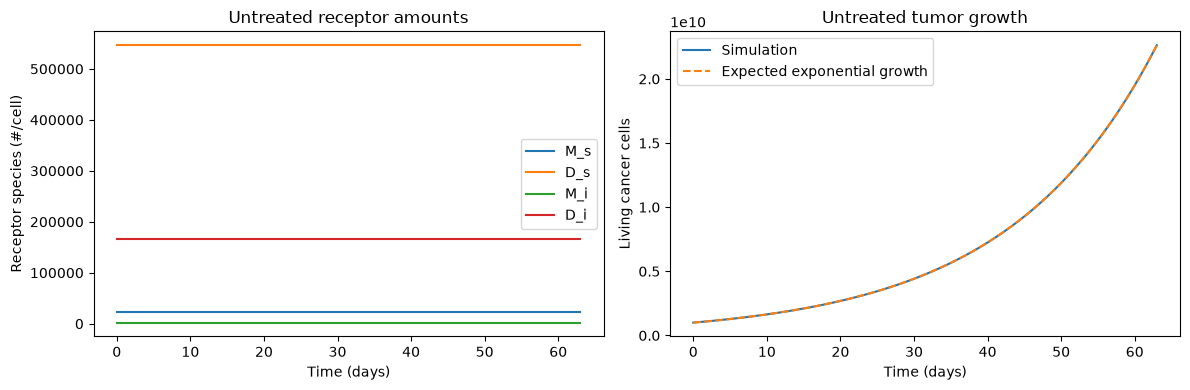

In [12]:
# simulates the untreated system and plot the receptor and cell-count time courses.
time_days = np.linspace(0, 63, 1000)
time_minutes = time_days * 24 * 60

untreated = Simulation(
    condition_name='Untreated system',
    t=time_minutes,
    model=model,
    initial_values=initial_values
)

result = untreated.simulate()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for species in ['M_s', 'D_s', 'M_i', 'D_i']:
    axes[0].plot(time_days, result[species], label=species)

axes[0].set_xlabel('Time (days)')
axes[0].set_ylabel('Receptor species (#/cell)')
axes[0].set_title('Untreated receptor amounts')
axes[0].legend()

N_expected = initial_values['N'] * np.exp(parameters.mu * time_minutes)

axes[1].plot(time_days, result['N'], label='Simulation')
axes[1].plot(time_days, N_expected, '--', label='Expected exponential growth')
axes[1].set_xlabel('Time (days)')
axes[1].set_ylabel('Living cancer cells')
axes[1].set_title('Untreated tumor growth')
axes[1].legend()

plt.tight_layout()
plt.show()

In [13]:
# Run this cell to add your answer (ordered text and image pages, with math/equations).
add_answer("milestone1_untreated")

### Model explorer

The model explorer shows how dose, dosing interval, and each kinetic parameter
affect your model. Run the next cell and click **Launch model explorer**. The
explorer opens in its own window, so keep the notebook kernel running. For each
simulation, it recalculates the untreated receptor steady state for the selected
parameter values, using your receptor initial conditions as a starting guess.
Your initial cell count is retained. Each parameter comparison therefore starts
at its own untreated receptor baseline. If you change your model, close the window
and launch it again.

Set the dose, the interval $\tau$ between doses (doses fall on days $0$, $\tau$, and
$2\tau$), and any parameter values, then click **Update Plots**. To see how much a
quantity matters, choose it from the **parameter sweep** menu and click
**Sweep Parameter** to overlay curves over a range around its current value.
**Reset Defaults** returns to the values at launch.

Use the explorer to get a feel for the model before you search for the smallest
effective dose. This exploration is ungraded, but a later question asks you to
use the explorer for a graded sweep.

In [14]:
dosing_demo = show_dosing_demo(
    lambda: (globals().get('model'), globals().get('initial_values'))
)

Launch model explorer: open the notebook to launch the separate window.

<style class="question-heading-css">
h2.question-heading, h3.question-heading,
h2:has(> .question-heading-marker), h3:has(> .question-heading-marker) {
  color: #7030A0;
  font-weight: bold;
  margin: 0;
  page-break-after: avoid;
  break-after: avoid;
}
h2.question-heading, h2:has(> .question-heading-marker) {
  font-size: 1.5em;
  text-align: center;
}
h3.question-heading, h3:has(> .question-heading-marker) {
  font-size: 1.1em;
}
.question-heading .question-heading-points,
h2:has(> .question-heading-marker) .question-heading-points,
h3:has(> .question-heading-marker) .question-heading-points {
  font-weight: normal;
}
</style>

## <span class="question-heading-marker" data-kind="standalone" data-number="4"></span>Problem 4. Choose a three-dose regimen <span class="question-heading-points">(30 pts — manual)</span>

Find the smallest dose, in increments of **0.1 mg/kg**, that achieves
$N(63\,\mathrm{days})/N_0\leq0.05$. Use three equal doses on days 0, 21, and 42,
with each dose positive and at most 4.5 mg/kg. Use the given kinetic parameters
and the same untreated receptor state and initial tumor for every regimen.

Compare at least **three different dose sizes**, including your selected dose
and the next lower dose. Show that the selected dose meets the target and the
next lower dose fails. Choose your own search method.

Plot loaded ADC in blood, released payload in blood, cytoplasmic payload, and
living-cell fraction over the 63 days. Report the selected dose per administration,
total dose, day-63 cell fraction, blood payload peak in ng/mL, and blood payload AUC
in μg·h/mL.
Explain the efficacy and exposure comparison.

You used <tt>Impulse</tt> in PSET 4. To give three doses, pass three impulses to a
single simulation. An impulse can give the dose as an amount in <tt>'mol'</tt>, which the
simulation converts to blood concentration using the blood volume. (Note that each
impulse represents an addition of Enhertu, not a reset of the concentration.)

<tt>result['A_b']</tt> gives the sampled concentration, <tt>result.in_days()</tt> gives time
in days, and <tt>result['N'][-1]</tt> gives the final cell count. <tt>result['AUC_P_b'][-1]</tt>
is the AUC from your accumulator, in M·min. Convert it to μg·h/mL using the payload
molecular weight.
For a plot, use Matplotlib or <tt>plot_simulations(result, variables=['A_b','N'], time_units='day')</tt>.
<tt>plot_simulations</tt> can also convert units for display. For example,
<tt>unit_conversions={'A_b': (factor, 'μg/mL')}</tt> multiplies <tt>A_b</tt> by <tt>factor</tt> and labels
its axis μg/mL.

1.0 mg/kg: 6.699% remaining : FAIL
1.1 mg/kg: 5.589% remaining : FAIL
1.2 mg/kg: 4.766% remaining : PASS


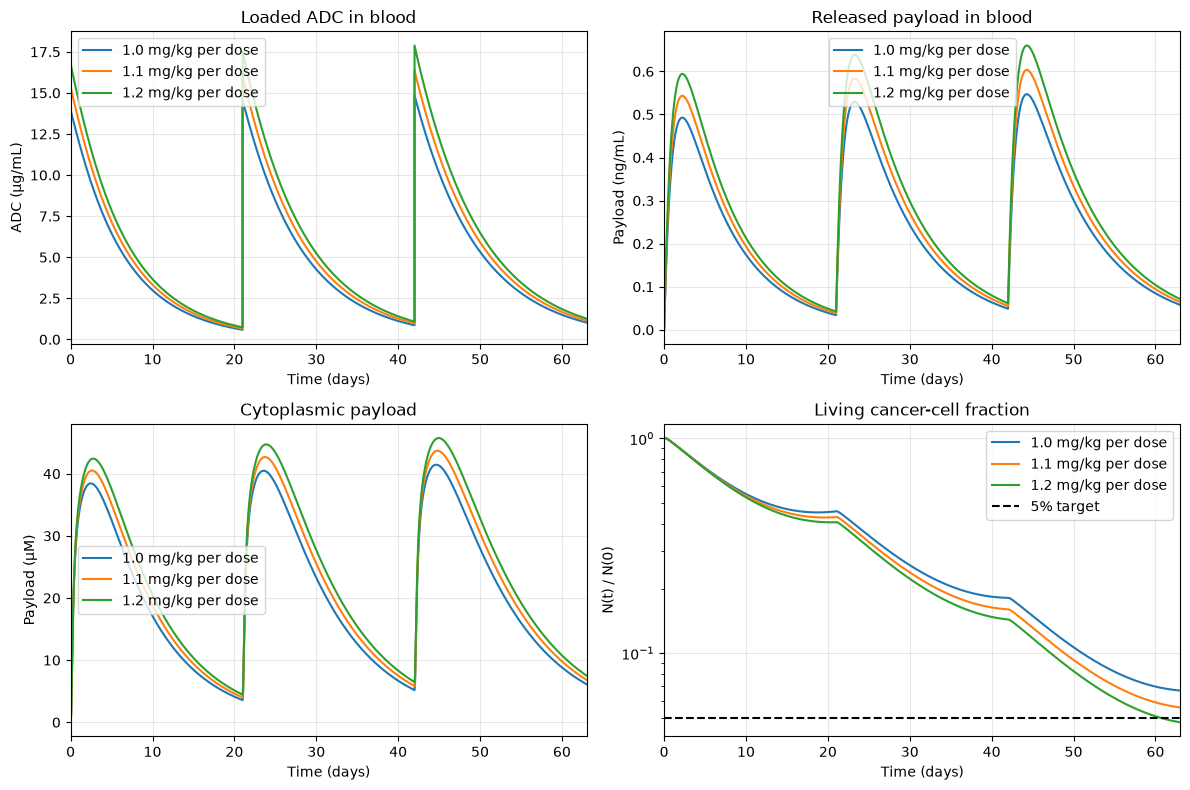


Selected dose: 1.2 mg/kg per administration
Total dose: 3.6 mg/kg
63-day percent remaining: 4.766%
Peak blood payload concentration: 0.660 ng/mL
Blood payload AUC: 0.426 µg·h/mL


In [15]:
# finds the smallest passing dose in 0.1 mg/kg increments and compare dose sizes.
dose_sizes_mg_per_kg = [1.0, 1.1, 1.2]
dose_days = [0, 21, 42]
regimen_results = []
comparison_results = []
chosen_result = None
ADC_MW = 156000 # g/mol
payload_MW = 1000
N_A = 6.022e23

def dose_to_moles(dose_mg_per_kg): # convert dose in mg/kg to moles of ADC for a 70 kg patient, given the molecular weight of the ADC
    patient_mass = 70
    return dose_mg_per_kg * patient_mass * 1e-3 / ADC_MW

for dose in dose_sizes_mg_per_kg:
    events = [
        Impulse(day * 1440, 'A_b', dose_to_moles(dose), 'mol')
        for day in dose_days
    ] # creates list of Impulse events (one event for each dose day, with the time in minutes) for the three doses, each with the same dose size in moles

    trial = Simulation(
        condition_name=f'{dose:.1f} mg/kg per dose',
        t=time_minutes,
        model=model,
        initial_values=initial_values.copy(), # copy to ensure that each trial starts with the same initial values
        impulses=events,
        method='LSODA',
        rtol=1e-8
    )

    result = trial.simulate()
    regimen_results.append(result)

    fraction_remaining = result['N'][-1] / initial_values['N']
    status = 'PASS' if fraction_remaining <= 0.05 else 'FAIL'

    print(
        f'{dose:.1f} mg/kg: '
        f'{100 * fraction_remaining:.3f}% remaining : {status}'
    )

passing_indices = []
 # stores the indices of the doses that pass the target fraction remaining of 0.05 (not the dose amount, just the index)
for i, result in enumerate(regimen_results):
    fraction_remaining = result['N'][-1] / initial_values['N']

    if fraction_remaining <= 0.05:
        passing_indices.append(i)

if not passing_indices:
    raise ValueError('None of the three doses met the target.')

chosen_index = passing_indices[0] # choose the first passing dose (smallest dose that meets the target fraction remaining of 0.05)

# reporting relevant simulation data for chosen dose
chosen_dose = dose_sizes_mg_per_kg[chosen_index]
chosen_result = regimen_results[chosen_index]
day63_fraction = chosen_result['N'][-1] / initial_values['N']
peak_payload_ng_per_mL = (np.max(chosen_result['P_b']) * payload_MW * 1e6) # M --> g/L --> ng/mL (1e6 conversion)
payload_AUC_ug_h_per_mL = (chosen_result['AUC_P_b'][-1] * payload_MW * 1e3 / 60) # M min --> g*min/L --> µg*h/mL (1e3 conversion from g/L to ug/mL and 1/60 conversion from min to h)

# To generate comparison plots for all three dose:
comparison_doses = dose_sizes_mg_per_kg.copy()
comparison_results = regimen_results.copy()

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for dose, result in zip(comparison_doses, comparison_results):
    days = result.in_days()
    label = f'{dose:.1f} mg/kg per dose'

    # Blood concentrations: M → mass/volume
    ADC_ug_per_mL = result['A_b'] * ADC_MW * 1e3
    payload_ng_per_mL = result['P_b'] * payload_MW * 1e6

    # Cytoplasmic payload:
    payload_uM = (result['P_c'] / (N_A * cell_volume_L)) * 1e6 # molecules/cell → M → µM

    cell_fraction = result['N'] / initial_values['N']

    axes[0, 0].plot(days, ADC_ug_per_mL, label=label)
    axes[0, 1].plot(days, payload_ng_per_mL, label=label)
    axes[1, 0].plot(days, payload_uM, label=label)
    axes[1, 1].semilogy(days, cell_fraction, label=label)

axes[0, 0].set_title('Loaded ADC in blood')
axes[0, 0].set_ylabel('ADC (µg/mL)')

axes[0, 1].set_title('Released payload in blood')
axes[0, 1].set_ylabel('Payload (ng/mL)')

axes[1, 0].set_title('Cytoplasmic payload')
axes[1, 0].set_ylabel('Payload (µM)')

axes[1, 1].set_title('Living cancer-cell fraction')
axes[1, 1].set_ylabel('N(t) / N(0)')
axes[1, 1].axhline(
    0.05, color='black', linestyle='--', label='5% target'
)

for ax in axes.flat:
    ax.set_xlabel('Time (days)')
    ax.set_xlim(0, 63)
    ax.legend()
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print(f'\nSelected dose: {chosen_dose:.1f} mg/kg per administration')
print(f'Total dose: {3 * chosen_dose:.1f} mg/kg')
print(f'63-day percent remaining: {100 * day63_fraction:.3f}%')
print(f'Peak blood payload concentration: {peak_payload_ng_per_mL:.3f} ng/mL')
print(f'Blood payload AUC: {payload_AUC_ug_h_per_mL:.3f} µg·h/mL')

In [16]:
# Run this cell to add your answer (ordered text and image pages, with math/equations).
add_answer("milestone1_regimen")

<style class="question-heading-css">
h2.question-heading, h3.question-heading,
h2:has(> .question-heading-marker), h3:has(> .question-heading-marker) {
  color: #7030A0;
  font-weight: bold;
  margin: 0;
  page-break-after: avoid;
  break-after: avoid;
}
h2.question-heading, h2:has(> .question-heading-marker) {
  font-size: 1.5em;
  text-align: center;
}
h3.question-heading, h3:has(> .question-heading-marker) {
  font-size: 1.1em;
}
.question-heading .question-heading-points,
h2:has(> .question-heading-marker) .question-heading-points,
h3:has(> .question-heading-marker) .question-heading-points {
  font-weight: normal;
}
</style>

## <span class="question-heading-marker" data-kind="standalone" data-number="5"></span>Problem 5. Explore the dosing interval <span class="question-heading-points">(10 pts — manual)</span>

Your regimen gives three equal doses 21 days apart. Does the spacing matter? The
model explorer can answer that in one sweep. Set the explorer's dose to your
selected dose, choose **Dose interval (days)** from the parameter sweep menu, and
click **Sweep Parameter**. Doses then fall on days $0$, $\tau$, and $2\tau$ for
intervals from about 2 to 31 days, so every curve delivers the same total dose.

Report the interval that leaves the fewest living cells on day 63, and explain
why much shorter and much longer intervals both do worse. Use the cytoplasmic
payload and living-cell plots in your explanation. Think about what limits the
killing rate when cytoplasmic payload is high, how long a dose keeps killing
going after it is given, and what the tumor does in between. Also note how the
blood payload peak and AUC change with the interval. Paste a screenshot of the
explorer window with your answer.

In [17]:
# Run this cell to add your answer (ordered text and image pages, with math/equations).
add_answer("milestone1_dose_interval")

## Submit Milestone 1

When you have finished the Milestone 1 questions, run the cell below to generate
your submission PDF, <tt>signed_results.json</tt>, and <tt>code.py</tt>, then upload
them to Gradescope.

In [18]:
if _instructor_source:
    print('Instructor source: build the assignment to generate the runnable template, solution, and submission files.')
else:
    from generate_pset_submission import generate_pset_submission
    generate_pset_submission()

📖 Loading notebook: NEWEST_Design_Project_Milestone_2.ipynb
   Found 3 auto-graded and 4 manually-graded questions
✅ Generated: code.py
✅ Generated: signed_results.json
⚠️  Question 2.1 occupies one page that is at least 4 A4 sheets tall. Check for accidental excessive output.
✅ Generated: answers_jhgunton.pdf (7 question pages)
✅ Copied: NEWEST_Design_Project_Milestone_2.ipynb

📦 Submission files ready in design_project_milestone_1_to_submit/ folder!
   Upload the files from design_project_milestone_1_to_submit to Gradescope:
   • signed_results.json → Autograder assignment (your recorded scores)
   • code.py → submission record
   • answers_jhgunton.pdf → Manual grading assignment
   • NEWEST_Design_Project_Milestone_2.ipynb → Full notebook (for reference/debugging)

✅ Finished at 2026-11-22 11:22:58


Button(button_style='info', description='📄 View PDF', layout=Layout(margin='10px 0', width='120px'), style=But…

## Milestone 2: Model modification

### How can you change the ADC to improve its efficacy or safety?

Together with your team members, identify an aspect of the model that can be
altered to improve performance of the ADC. You are looking for modifications
that allow the ADC to eliminate cancer cells at a faster rate or at a lower dose
or that would reduce payload toxicity.

Changing the value of a parameter can meet the requirements, but a creative
modification grounded in the biology of the ADC system will tend to score better.
Aim for creativity in your understanding and analysis of the system. The
[project references](#project-references) can help you brainstorm ideas.

Use your Milestone 1 model as the starting point. Explain why you chose your
modification and whether it has biological relevance. Provide a schematic and
any new rate equations required to describe your modified system, and explicitly
state its assumptions.

Explain the results of your model modification. How does the modification affect
the model? Did you have an a priori prediction as to the impact? Do the results
agree with your prediction? What did you learn about what makes a good ADC from
this model modification?

## Final project report

Your final report should bring together the base-model analysis and the
biological modification:

1. Provide a brief written summary of the system, including a schematic diagram
   with rate constants and the rate equations with units. Highlight the
   biological reasoning behind your model. Diagrams and equations can be included
   in an appendix as needed.
2. Assess the temporal performance of the base model without ADC and for at least
   three dose sizes, using the Milestone 1 regimen and target. Report the selected
   dose per administration, total dose, and final cell fraction, show that the next
   lower dose fails, and support the choice with blood payload peak and AUC.
3. Explain your model modification, its biological relevance, and the schematic
   and any new rate equations needed to describe it.
4. Explain the effects of the modification, compare the results with your a
   priori prediction, and discuss what you learned about what makes a good ADC.

Explicitly state all assumptions used in generating and implementing your model.

**Page limit:** do not exceed **8 pages**, double-spaced with **12-point font**.
Figures do not count toward the 8-page limit. This limit applies to the final
project report, not to the automatically generated Milestone 1 submission PDF.

<a id="project-references"></a>

## Project references

### Example ADC trafficking and pharmacokinetic models

Maass KF, Kulkarni C, Betts AM, Wittrup KD. Determination of Cellular Processing Rates for a Trastuzumab-Maytansinoid Antibody-Drug Conjugate (ADC) Highlights Key Parameters for ADC Design. AAPS J. 2016;18(3):635–646. [doi:10.1208/s12248-016-9892-3](https://doi.org/10.1208/s12248-016-9892-3).

Singh AP, Shah DK. Application of a PK-PD Modeling and Simulation-Based Strategy for Clinical Translation of Antibody-Drug Conjugates: a Case Study with Trastuzumab Emtansine (T-DM1). AAPS J. 2017;19(4):1054–1070. [doi:10.1208/s12248-017-0071-y](https://doi.org/10.1208/s12248-017-0071-y).

Menezes B, Cilliers C, Wessler T, Thurber GM, Linderman JJ. An Agent-Based Systems Pharmacology Model of the Antibody-Drug Conjugate Kadcyla to Predict Efficacy of Different Dosing Regimens. AAPS J. 2020;22(2):29. [doi:10.1208/s12248-019-0391-1](https://doi.org/10.1208/s12248-019-0391-1).

Betts A, Clark T, Jasper P, et al. Use of translational modeling and simulation for quantitative comparison of PF-06804103, a new generation HER2 ADC, with Trastuzumab-DM1. J Pharmacokinet Pharmacodyn. 2020;47(5):513–526. [doi:10.1007/s10928-020-09702-3](https://doi.org/10.1007/s10928-020-09702-3).

### Resources to inform possible model modifications

Ritchie M, Tchistiakova L, Scott N. Implications of receptor-mediated endocytosis and intracellular trafficking dynamics in the development of antibody drug conjugates. MAbs. 2013;5(1):13–21. [doi:10.4161/mabs.22854](https://doi.org/10.4161/mabs.22854).

This review discusses how trafficking of the targeted receptor (HER2 in our system) can influence ADC efficacy. Can you think of a way to change how the ADC binds to HER2 monomers and/or dimers that would change its trafficking?

Lyon RP, Setter JR, Bovee TD, et al. Self-hydrolyzing maleimides improve the stability and pharmacological properties of antibody-drug conjugates. Nat Biotechnol. 2014;32(10):1059–1062. [doi:10.1038/nbt.2968](https://doi.org/10.1038/nbt.2968).

This paper developed a new kind of chemical linker to attach cytotoxic drugs to antibodies, which slowed release of drug in circulation and thus reduced toxic side effects associated with premature payload release.

Loganzo F, Tan X, Sung M, et al. Tumor cells chronically treated with a trastuzumab-maytansinoid antibody-drug conjugate develop varied resistance mechanisms but respond to alternate treatments. Mol Cancer Ther. 2015;14(4):952–963. [doi:10.1158/1535-7163.MCT-14-0862](https://doi.org/10.1158/1535-7163.MCT-14-0862).

This paper showed that reduced HER2 expression was one mechanism of resistance in cancer cells chronically treated with a trastuzumab-maytansinoid ADC. Could you design your ADC so that it retains its ability to kill cancer cells even if they evolve to reduce their HER2 expression level?

Tsui CK, Barfield RM, Fischer CR, et al. CRISPR-Cas9 screens identify regulators of antibody-drug conjugate toxicity. Nat Chem Biol. 2019;15(10):949–958. [doi:10.1038/s41589-019-0342-2](https://doi.org/10.1038/s41589-019-0342-2).

This paper identified multiple biological regulators of toxicity of a HER2-targeted ADC expressed in cancer cells, offering opportunities for combination therapy strategies to improve ADC efficacy against their tumor targets.

Tsao LC, Wang JS, Ma X, et al. Effective extracellular payload release and immunomodulatory interactions govern the therapeutic effect of trastuzumab deruxtecan (T-DXd). Nat Commun. 2025;16(1):3167. [doi:10.1038/s41467-025-58266-8](https://doi.org/10.1038/s41467-025-58266-8).

In some settings, Enhertu can elicit an immune response to cancer, which contributes to its overall efficacy and the durability of patient responses. Can you think of a simple way to model the immune effects of the Enhertu ADC?

Kumagai K, Aida T, Tsuchiya Y, Kishino Y, Kai K, Mori K. Interstitial pneumonitis related to trastuzumab deruxtecan, a human epidermal growth factor receptor 2-targeting Ab-drug conjugate, in monkeys. Cancer Sci. 2020;111(12):4636–4645. [doi:10.1111/cas.14686](https://doi.org/10.1111/cas.14686).

This study implicates uptake of intact ADC by alveolar macrophages in lung toxicity in monkeys. What toxicity mechanisms could the base model miss when it compares designs using released-payload exposure in blood?

In [19]:
### Creating new model class to handle cardiomyocyte growth, which uses a different growth parameter than tumor cells.
### This is necessary to avoid ValueError when building the model with the cardiomyocyte compartment.

from design_project_helpers import ModelWithoutDilution, ChemicalSpecies

class ModelWithoutDilutionV2(ModelWithoutDilution):
    def rhs(self, t, state):
        derivatives = super().rhs(t, state)

        for i, name in enumerate(self.species_names):
            species = self.species(name)

            if species.units == '#/cell':
                count = species.compartment.count_variable

                if count == 'N_h':
                    derivatives[i] += (
                        self.parameters['mu_h'] - self.parameters['mu']
                    ) * state[i]

                elif count == 'N_e':
                    derivatives[i] -= self.parameters['mu'] * state[i]

        return derivatives


def build_model_v2(network, parameters, time_units='min'):
    # Each cell population uses its own growth parameter.
    growth_parameters = {
        'N': 'mu',
        'N_h': 'mu_h'
    }

    for compartment in network.replicated_compartments:
        # Only check compartments containing molecular species.
        if not any(
            isinstance(species, ChemicalSpecies)
            and species.compartment is compartment
            for species in network.species.values()
        ):
            continue

        count = compartment.count_variable
        if count == 'N_e':
        # Verify that the epithelial population really is constant.
            if any(
                count in reaction.reactants or count in reaction.products
                for reaction in network.reactions
            ):
                raise ValueError(
                    'N_e is modeled as constant; do not add cell-count reactions.'
                )

            if any(term.species == count for term in network.direct_terms):
                raise ValueError(
                    'N_e is modeled as constant; do not add cell-count rate terms.'
                )

            continue
        expected_rate = growth_parameters[count]

        growth = [
            reaction
            for reaction in network.reactions
            if reaction.net_stoichiometry.get(count, 0) > 0
        ]

        if len(growth) != 1 or not (
            growth[0].reactants == {count: 1}
            and growth[0].products == {count: 2}
            and growth[0].forward_rate_constant == expected_rate
            and growth[0].rate_function is None
            and not growth[0].is_reversible
        ):
            raise ValueError(
                f"Use one irreversible '{count} -> 2 {count}' reaction "
                f"with rate constant '{expected_rate}'."
            )

        if any(
            term.species == count
            for term in network.direct_terms
        ):
            raise ValueError(
                'Use reactions to describe cell growth and death.'
            )

    return ModelWithoutDilutionV2(network, parameters, time_units=time_units)

In [20]:
### Milestone 2 Modification Code

# Cardiomyocyte compartment parameters
V_cell_h = 2.5e-11
N_h_0 = 3.2e9
N_h_uncertainty = 0.75e9 # +/- N_h_0 according to paper

# Target untreated surface HER2 abundance
R_s_h_target = 1.0e5         # HER2 receptor subunits per cell

# Drug-to-antibody ratio
X = 8                             # Baseline; change for modified ADC comparisons

# adds heart compartment
network.add_compartment(Compartment(
    'heart',
    count_variable='N_h',
    count_units='cells',
    volume_per_unit=V_cell_h
))

# other heart-specific parameters
parameters.add(
    'q_HER2_h',
    66.6,
    '#/cell/min',
    'Cardiomyocyte HER2 monomer synthesis'
)

# Converting k_on_HER2 from M^-1s^-1 to (#/cell)^-1 min^-1
k_on_HER2_h_per_cell = convert_rate_constant(
    1e5 * 60, # same as k_on_HER2 (in M^-1min^-1) for tumor cell dimerization
    'M^-1 min^-1',
    '(#/cell)^-1 min^-1',
    volume=V_cell_h
)

parameters.add(
    'k_on_HER2_h',
    k_on_HER2_h_per_cell,
    '(#/cell)^-1 min^-1',
    'Cardiomyocyte HER2 dimer association'
)

# cardiomyocyte proliferation placeholder (in case we'd like to vary this parameter later)
parameters.add(
    'mu_h',
    0.0,
    'min^-1',
    'Cardiomyocyte growth rate'
)

# Same killing parameters as tumor
parameters.add(
    'delta_max_h',
    parameters.delta_max,
    'min^-1',
    'Assumed maximum cardiomyocyte killing rate'
)

parameters.add(
    'K_P_h',
    parameters.K_P,
    'M',
    'Assumed cardiac payload concentration for half-maximal killing'
)

# adding heart species
network.add_species('M_s_h', 'Heart surface HER2 monomer', '#/cell', 'heart')
network.add_species('D_s_h', 'Heart surface HER2 dimer', '#/cell', 'heart')
network.add_species('C_s_h', 'Heart surface ADC-HER2 complex', '#/cell', 'heart')

network.add_species('M_i_h', 'Heart internal HER2 monomer', '#/cell', 'heart')
network.add_species('D_i_h', 'Heart internal HER2 dimer', '#/cell', 'heart')
network.add_species('A_i_h', 'Heart internal loaded ADC', '#/cell', 'heart')

network.add_species('P_i_h', 'Heart endosomal free payload', '#/cell', 'heart')
network.add_species('P_c_h', 'Heart cytoplasmic free payload', '#/cell', 'heart')

convert_rate_constant: 6e+06 M^-1 min^-1 × 6.642e-14 = 3.985e-07 (#/cell)^-1 min^-1 (N_Av × 2.5e-11 L = 1.506e+13 molecules per cell per molar)


In [21]:
### adding heart reactions (same as tumor, but with heart-specific parameters and species)

# HER2 heart synthesis
network.add_reaction(Reaction(
    'Heart HER2 synthesis',
    {}, 'M_s_h',
    forward_rate_constant='q_HER2_h'
))

# HER2 heart dimerization
network.add_reaction(Reaction(
    'Heart HER2 dimerization',
    '2 M_s_h', 'D_s_h',
    forward_rate_constant='k_on_HER2_h',
    reverse_rate_constant='k_off_HER2'
))

# ADC binding to a cardiac surface monomer
network.add_reaction(Reaction(
    'Heart ADC binding',
    'A_b + M_s_h', 'C_s_h',
    forward_rate_constant='k_on_ADC',
    reverse_rate_constant='k_off_ADC'
))

# Receptor internalization and recycling
network.add_reaction(Reaction(
    'Heart monomer recycling',
    'M_i_h', 'M_s_h',
    forward_rate_constant='k_rec',
    reverse_rate_constant='k_er'
))

network.add_reaction(Reaction(
    'Heart dimer recycling',
    'D_i_h', 'D_s_h',
    forward_rate_constant='k_rec',
    reverse_rate_constant='k_ec'
))

# Receptor degradation
network.add_reaction(Reaction(
    'Heart internal monomer degradation',
    'M_i_h', {},
    forward_rate_constant='k_deg_HER2'
))

network.add_reaction(Reaction(
    'Heart internal dimer degradation',
    'D_i_h', {},
    forward_rate_constant='k_deg_HER2'
))

# Complex internalization, followed by rapid ADC-HER2 dissociation
network.add_reaction(Reaction(
    'Heart ADC-HER2 internalization',
    'C_s_h', 'M_i_h + A_i_h',
    forward_rate_constant='k_er'
))

# Payload release
network.add_reaction(Reaction(
    'Heart endosomal payload release',
    'A_i_h', f'{X} P_i_h', # f-string to allow for variable drug-to-antibody ratio
    forward_rate_constant='k_rel_i'
))

# Payload escape into cytoplasm
network.add_reaction(Reaction(
    'Heart payload escape',
    'P_i_h', 'P_c_h',
    forward_rate_constant='k_esc'
))

# Payload degradation in either endosome or cytoplasm
network.add_reaction(Reaction(
    'Heart endosomal payload degradation',
    'P_i_h', {},
    forward_rate_constant='k_deg_P'
))

network.add_reaction(Reaction(
    'Heart cytoplasmic payload degradation',
    'P_c_h', {},
    forward_rate_constant='k_deg_P'
))

# Replacing original tumor payload reactions to incorporate modified X
network.add_reaction(Reaction(
    'Endosomal payload release',
    'A_i', f'{X} P_i',
    forward_rate_constant='k_rel_i'
))

network.add_reaction(Reaction(
    'Circulating payload release',
    'A_b', f'{X} P_b',
    forward_rate_constant='k_rel_b'
))

# Cardiomyocyte Killing (same Monod kinetics as tumor, but with heart-specific parameters)
def heart_killing_rate_constant(s, k):
    P_c_h_M = s.molar('P_c_h') # convert cytoplasmic payload concentration from #/cell to moles/L
    return (k.delta_max_h * P_c_h_M) / (k.K_P_h + P_c_h_M)

network.add_reaction(Reaction(
    'Heart cell killing', 'N_h', {},
    rate_function=lambda s, k: heart_killing_rate_constant(s, k) * s.N_h,
    rate_expression='delta_h × [N_h]', rate_expression_latex=r'\delta_h \, [N_h]',
    rate_units='cells/min'
))

# Placeholder for cardiomyocyte growth: addresses ValueError of expected growth reaction in cardiomyocyte compartment

network.add_reaction(Reaction(
    'Heart cell growth',
    'N_h', '2 N_h',
    forward_rate_constant='mu_h'
))

# accumulator for P_c_h (one method of determining cardiac toxicity)
network.add_accumulator(
    'AUC_P_c_h',
    lambda s, k: s.molar('P_c_h'),
    'M min',
    'Area under the curve of cardiac cytoplasmic payload concentration over time'
)

model_v2 = build_model_v2(network, parameters, time_units='min')

model_v2.print_rate_equations()

Per-cell species are in molecules per cell; N, N_h is the cell count (= ρV in the lecture). Molar balances are written multiplied through by N_Av V, as in the lecture.


<IPython.core.display.Math object>

    d[N]/dt = mu × [N] - delta × [N]    (Count of cell)


<IPython.core.display.Math object>

    N_Av V_blood d[A_b]/dt = - N × k_on_ADC × [A_b] × [M_s] + N × k_off_ADC × [C_s] - N_Av V_blood × k_rel_b × [A_b] - N_Av V_blood × k_clear_ADC × [A_b] - N_h × k_on_ADC × [A_b] × [M_s_h] + N_h × k_off_ADC × [C_s_h]    (Loaded ADC in blood)


<IPython.core.display.Math object>

... (31 outputs left out)

<IPython.core.display.Math object>

    d[P_i_h]/dt = 8 × k_rel_i × [A_i_h] - k_esc × [P_i_h] - k_deg_P × [P_i_h]    (Heart endosomal free payload)


<IPython.core.display.Math object>

    d[P_c_h]/dt = k_esc × [P_i_h] - k_deg_P × [P_c_h]    (Heart cytoplasmic free payload)


In [22]:
### Adding Epithelial Compartment and Species for HER2 trafficking in epithelial cells

# 1. Epithelial Compartment (held at constant N_e = N_e_0 cells)
epi_cell_volume_L = 2.0e-12  # 2,000 um^3 converted to L
network.add_compartment(
    Compartment(
        'epithelium',
        count_variable='N_e',
        count_units='cells',
        volume_per_unit=epi_cell_volume_L,
    )
)

# 2. Epithelial Species (surface and endosomal receptor trafficking only)
network.add_species('M_se', 'Epithelial surface monomer', '#/cell', 'epithelium')
network.add_species('D_se', 'Epithelial surface dimer', '#/cell', 'epithelium')
network.add_species('C_se', 'Epithelial surface ADC-monomer complex', '#/cell', 'epithelium')
network.add_species('M_ie', 'Epithelial internal monomer', '#/cell', 'epithelium')
network.add_species('D_ie', 'Epithelial internal dimer', '#/cell', 'epithelium')

# 3. Epithelial-Specific Parameters (yields 2.0e4 accessible surface HER2 molecules/cell)
N_e_0 = 2.0e9            # Accessible vascular-facing HER2+ epithelial cells
R_s_e_target = 2.0e4     # Physiological IHC 0/1+ surface HER2 density (receptors/cell)

k_on_HER2_e_per_cell = convert_rate_constant(
    1e5 * 60,  # k_on_HER2 in M^-1 min^-1
    'M^-1 min^-1',
    '(#/cell)^-1 min^-1',
    volume=epi_cell_volume_L,
)
parameters.add('k_on_HER2_e', k_on_HER2_e_per_cell, '(#/cell)^-1 min^-1', 'Epithelial HER2 dimer association rate')

# Compute q_HER2_e from R_s_e_target so untreated surface HER2 matches target
f_e = parameters.k_deg_HER2 / (parameters.k_rec + parameters.k_deg_HER2)
alpha_e = parameters.k_on_HER2_e / (parameters.k_off_HER2 + f_e * parameters.k_ec)
M_se_ss = (-1 + np.sqrt(1 + 8 * alpha_e * R_s_e_target)) / (4 * alpha_e)
q_HER2_e_val = f_e * parameters.k_er * M_se_ss + 2 * f_e * parameters.k_ec * alpha_e * M_se_ss**2

parameters.add('q_HER2_e', q_HER2_e_val, '#/cell/min', 'Epithelial HER2 monomer synthesis')

# 4. Epithelial Sink Reactions (10 reactions; no growth or death for N_e)
network.add_reaction(
    Reaction('Epithelial HER2 synthesis', {}, 'M_se', forward_rate_constant='q_HER2_e')
)
network.add_reaction(
    Reaction(
        'Epithelial HER2 dimerization',
        '2 M_se',
        'D_se',
        forward_rate_constant='k_on_HER2_e',
        reverse_rate_constant='k_off_HER2',
    )
)
network.add_reaction(
    Reaction(
        'Epithelial ADC binding',
        'A_b + M_se',
        'C_se',
        forward_rate_constant='k_on_ADC',
        reverse_rate_constant='k_off_ADC',
    )
)
network.add_reaction(
    Reaction('Epithelial monomer internalization', 'M_se', 'M_ie', forward_rate_constant='k_er')
)
network.add_reaction(
    Reaction('Epithelial dimer internalization', 'D_se', 'D_ie', forward_rate_constant='k_ec')
)
network.add_reaction(
    Reaction('Epithelial monomer recycling', 'M_ie', 'M_se', forward_rate_constant='k_rec')
)
network.add_reaction(
    Reaction('Epithelial dimer recycling', 'D_ie', 'D_se', forward_rate_constant='k_rec')
)
network.add_reaction(
    Reaction('Epithelial internal monomer degradation', 'M_ie', {}, forward_rate_constant='k_deg_HER2')
)
network.add_reaction(
    Reaction('Epithelial internal dimer degradation', 'D_ie', {}, forward_rate_constant='k_deg_HER2')
)
# ADC-monomer internalization clears bound ADC into the epithelial sink
network.add_reaction(
    Reaction('Epithelial C_se internalization', 'C_se', 'M_ie', forward_rate_constant='k_er')
)

# initial values for epithelial compartment (N_e = N_e_0 cells, steady-state receptor values)
D_se_ss = alpha_e * M_se_ss**2
M_ie_ss = (parameters.k_er / (parameters.k_rec + parameters.k_deg_HER2)) * M_se_ss
D_ie_ss = (parameters.k_ec / (parameters.k_rec + parameters.k_deg_HER2)) * D_se_ss

initial_values.update({
    'N_e': N_e_0,
    'M_se': M_se_ss,
    'D_se': D_se_ss,
    'C_se': 0.0,
    'M_ie': M_ie_ss,
    'D_ie': D_ie_ss,
})

convert_rate_constant: 6e+06 M^-1 min^-1 × 8.303e-13 = 4.982e-06 (#/cell)^-1 min^-1 (N_Av × 2e-12 L = 1.204e+12 molecules per cell per molar)


In [23]:
### Calculating steady state receptor values for cardiomyocytes, using the same approach (i.e., finding M_s_h_ss via quadratic formula) as for tumor cells

f_h = parameters.k_deg_HER2 / (parameters.k_rec + parameters.k_deg_HER2)

alpha_h = parameters.k_on_HER2_h / (parameters.k_off_HER2 + f_h * parameters.k_ec)

a_h = 2 * f_h * parameters.k_ec * alpha_h
b_h = f_h * parameters.k_er
c_h = -parameters.q_HER2_h

M_s_h_ss = (-b_h + np.sqrt(b_h**2 - 4 * a_h * c_h)) / (2 * a_h)

D_s_h_ss = alpha_h * M_s_h_ss**2

M_i_h_ss = (parameters.k_er / (parameters.k_rec + parameters.k_deg_HER2)) * M_s_h_ss

D_i_h_ss = (parameters.k_ec / (parameters.k_rec + parameters.k_deg_HER2)) * D_s_h_ss

# Copies initial values from the original model and updates them with the new cardiomyocyte initial values
initial_values_v2 = initial_values.copy()

initial_values_v2.update({
    'N_h': N_h_0,

    'M_s_h': M_s_h_ss,
    'D_s_h': D_s_h_ss,
    'M_i_h': M_i_h_ss,
    'D_i_h': D_i_h_ss,

    # Same assumption as before: no drug in the system, so all drug species start at zero
    'C_s_h': 0.0,
    'A_i_h': 0.0,
    'P_i_h': 0.0,
    'P_c_h': 0.0,
    'A_b': 0.0,
    'P_b': 0.0,
    'C_s': 0.0,
    'A_i': 0.0,
    'P_i': 0.0,
    'P_c': 0.0,

    'AUC_P_b': 0.0,
    'AUC_P_c_h': 0.0
})

# Printing the initial values for cardiomyocyte species to verify correctness
for species in ['M_s_h', 'D_s_h', 'M_i_h', 'D_i_h']:
    print(f"{species}: {initial_values_v2[species]:,.2f} #/cell")

R_surface_h_ss = M_s_h_ss + 2 * D_s_h_ss

print(f"\nSurface HER2: {R_surface_h_ss:,.2f} receptors/cell")
print(f"Target: {R_s_h_target:,.2f} receptors/cell")
print(f"Initial cardiomyocytes: {initial_values_v2['N_h']:.3e} cells")

# Calculating steady state receptor values for epithelial cells, using the same approach (i.e., finding M_s_e_ss via quadratic formula) as for tumor cells

N_e_0 = 2.0e9            # Accessible vascular-facing HER2+ epithelial cells
R_s_e_target = 2.0e4     # Physiological IHC 0/1+ surface HER2 density (receptors/cell)

f_e = parameters.k_deg_HER2 / (parameters.k_rec + parameters.k_deg_HER2)

alpha_e = parameters.k_on_HER2_e / (parameters.k_off_HER2 + f_e * parameters.k_ec)

a_e = 2 * f_e * parameters.k_ec * alpha_e
b_e = f_e * parameters.k_er
c_e = -parameters.q_HER2_e

M_s_e_ss = (-b_e + np.sqrt(b_e**2 - 4 * a_e * c_e)) / (2 * a_e)

D_s_e_ss = alpha_e * M_s_e_ss**2

M_i_e_ss = (parameters.k_er / (parameters.k_rec + parameters.k_deg_HER2)) * M_s_e_ss

D_i_e_ss = (parameters.k_ec / (parameters.k_rec + parameters.k_deg_HER2)) * D_s_e_ss

# Updates initial_values_v2 with the new epithelial sink initial values
# Keys match the species names declared in the network.
initial_values_v2.update({
    'N_e': N_e_0,
    'M_se': M_s_e_ss,
    'D_se': D_s_e_ss,
    'M_ie': M_i_e_ss,
    'D_ie': D_i_e_ss,
    'C_se': 0.0,
})

for species in ['M_se', 'D_se', 'M_ie', 'D_ie']:
    print(f"{species}: {initial_values_v2[species]:,.2f} #/cell")

R_surface_e_ss = M_s_e_ss + 2 * D_s_e_ss

print(f"\nSurface HER2: {R_surface_e_ss:,.2f} receptors/cell")
print(f"Target: {R_s_e_target:,.2f} receptors/cell")
print(f"Initial epithelial cells: {initial_values_v2['N_e']:.3e} cells")

M_s_h: 38,282.27 #/cell
D_s_h: 30,887.66 #/cell
M_i_h: 3,480.21 #/cell
D_i_h: 9,359.90 #/cell

Surface HER2: 100,057.59 receptors/cell
Target: 100,000.00 receptors/cell
Initial cardiomyocytes: 3.200e+09 cells
M_se: 5,284.69 #/cell
D_se: 7,357.65 #/cell
M_ie: 480.43 #/cell
D_ie: 2,229.59 #/cell

Surface HER2: 20,000.00 receptors/cell
Target: 20,000.00 receptors/cell
Initial epithelial cells: 2.000e+09 cells


Max relative drift over 63 days, cardiomyocyte receptors:
  M_s_h: 1.15e-11
  D_s_h: 1.12e-11
  M_i_h: 1.12e-11
  D_i_h: 6.35e-11

N_h(63 d)/N_h(0) = 1.000000  (expect 1.000000)
N(63 d)/N(0)     = 22.6274  (expect 2^(63/14) = 22.6274)
Largest cardiac payload untreated: 2.46e-20 #/cell  (expect 0)

Free monomer: 38,282 per cardiomyocyte vs 23,304 per cancer cell   <-- the ADC binds monomer only
Epithelial receptor maximum relative drift:
M_se: 4.28e-11
D_se: 3.88e-11
M_ie: 2.27e-11
D_ie: 8.08e-11
Epithelial cell-count maximum relative drift: 0.00e+00


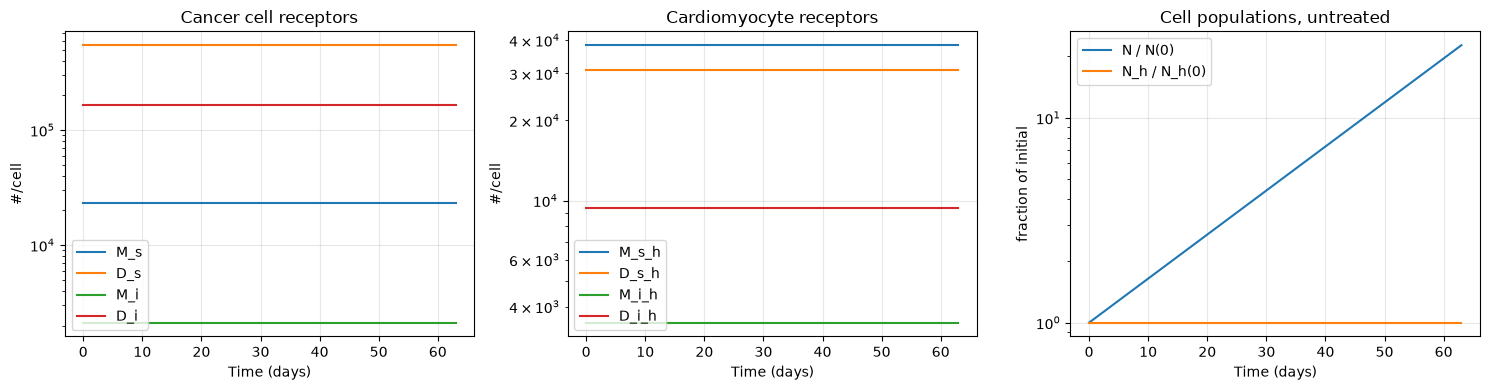

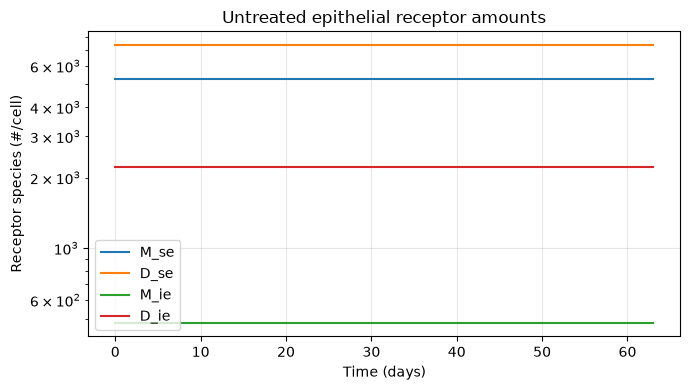

In [34]:
# adding DAR as a switch + simulating untreated baseline for both tissues to validate new model

def set_DAR(X, params=None):
    """Rebuild the model with drug-to-antibody ratio X. Returns the model."""
    network.add_reaction(Reaction(
        'Endosomal payload release', 'A_i', f'{X} P_i',
        forward_rate_constant='k_rel_i'))
    network.add_reaction(Reaction(
        'Circulating payload release', 'A_b', f'{X} P_b',
        forward_rate_constant='k_rel_b'))
    network.add_reaction(Reaction(
        'Heart endosomal payload release', 'A_i_h', f'{X} P_i_h',
        forward_rate_constant='k_rel_i'))
    return build_model_v2(network, parameters if params is None else params,
                       time_units='min')


def q_HER2_h_for(target_surface, k_on_h=None):
    """
    The q_HER2_h that puts untreated surface HER2 at target_surface per cell.

    Inverts the steady-state relation from the cell above, so receptor
    abundance (the literature-sourced quantity) is the knob and q_HER2_h
    follows from it. Used by the sensitivity sweep further down.
    """
    k_on = parameters.k_on_HER2_h if k_on_h is None else k_on_h
    alpha = k_on / (parameters.k_off_HER2 + f_h * parameters.k_ec)
    M_s = (-1 + np.sqrt(1 + 8 * alpha * target_surface)) / (4 * alpha)
    return f_h * parameters.k_er * M_s + 2 * f_h * parameters.k_ec * alpha * M_s**2


steady_state_h = {'M_s_h': M_s_h_ss, 'D_s_h': D_s_h_ss,
                  'M_i_h': M_i_h_ss, 'D_i_h': D_i_h_ss}

new_model_v2 = set_DAR(8)

untreated_v2 = Simulation(
    condition_name='Untreated, tumor + heart',
    t=time_minutes,
    model=new_model_v2,
    initial_values=dict(initial_values_v2),
).simulate()

print("Max relative drift over 63 days, cardiomyocyte receptors:")
for s, v in steady_state_h.items():
    print(f"  {s}: {np.max(np.abs(untreated_v2[s] / v - 1)):.2e}")
print(f"\nN_h(63 d)/N_h(0) = {untreated_v2['N_h'][-1] / N_h_0:.6f}  (expect 1.000000)")
print(f"N(63 d)/N(0)     = {untreated_v2['N'][-1] / initial_values['N']:.4f}  "
      f"(expect 2^(63/14) = {2 ** (63 / 14):.4f})")
print(f"Largest cardiac payload untreated: {np.max(untreated_v2['P_c_h']):.2e} #/cell  (expect 0)")
print(f"\nFree monomer: {M_s_h_ss:,.0f} per cardiomyocyte vs "
      f"{steady_state['M_s']:,.0f} per cancer cell   <-- the ADC binds monomer only")
print("Epithelial receptor maximum relative drift:")
for species in ['M_se', 'D_se', 'M_ie', 'D_ie']:
    drift = np.max(np.abs(
        untreated_v2[species] / initial_values_v2[species] - 1
    ))
    print(f"{species}: {drift:.2e}")

count_drift = np.max(np.abs(
    untreated_v2['N_e'] / initial_values_v2['N_e'] - 1
))
print(f"Epithelial cell-count maximum relative drift: {count_drift:.2e}")

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for s in ['M_s', 'D_s', 'M_i', 'D_i']:
    axes[0].plot(untreated_v2.in_days(), untreated_v2[s], label=s)
axes[0].set_title('Cancer cell receptors'); axes[0].set_ylabel('#/cell')
for s in ['M_s_h', 'D_s_h', 'M_i_h', 'D_i_h']:
    axes[1].plot(untreated_v2.in_days(), untreated_v2[s], label=s)
axes[1].set_title('Cardiomyocyte receptors'); axes[1].set_ylabel('#/cell')
axes[0].set_yscale('log'); axes[1].set_yscale('log')
axes[2].plot(untreated_v2.in_days(), untreated_v2['N'] / initial_values['N'], label='N / N(0)')
axes[2].plot(untreated_v2.in_days(), untreated_v2['N_h'] / N_h_0, label='N_h / N_h(0)')
axes[2].set_title('Cell populations, untreated'); axes[2].set_ylabel('fraction of initial')
axes[2].set_yscale('log')
for ax in axes:
    ax.set_xlabel('Time (days)'); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

# Plotting Epithelial Steady State Receptor Values
fig, ax = plt.subplots(figsize=(7, 4))

for species in ['M_se', 'D_se', 'M_ie', 'D_ie']:
    ax.plot(
        untreated_v2.in_days(),
        untreated_v2[species],
        label=species
    )

ax.set_title('Untreated epithelial receptor amounts')
ax.set_xlabel('Time (days)')
ax.set_ylabel('Receptor species (#/cell)')
ax.set_yscale('log')
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [29]:
# run experiment with DAR 8 vs DAR 4, with q_HER2_h adjusted to keep surface HER2 at 1e5 per cell

def run_regimen(dose_mg_per_kg, model_, initial_):
    events = [Impulse(day * minutes_per_day, 'A_b',
                      dose_to_moles(dose_mg_per_kg), 'mol')
              for day in dose_days]
    return Simulation(
        condition_name=f'{dose_mg_per_kg:.1f} mg/kg',
        t=time_minutes, model=model_, initial_values=dict(initial_),
        impulses=events, method='LSODA', rtol=1e-8,
    ).simulate()


def smallest_passing_dose(model_, initial_, step=0.1, lo=0.05, hi=4.5):
    """Smallest dose on the `step` grid with N(63 d)/N(0) <= 0.05.

    Bisects on a continuous dose, then rounds up to the grid: ~13 simulations
    instead of scanning all 45 grid points.
    """
    def fraction(d):
        return run_regimen(d, model_, initial_)['N'][-1] / initial_['N']

    if fraction(hi) > target_fraction_remaining:
        return None, None
    a, b = lo, hi
    for _ in range(12):
        mid = 0.5 * (a + b)
        if fraction(mid) <= target_fraction_remaining:
            b = mid
        else:
            a = mid
    dose = round(np.ceil(b / step) * step, 1)
    return dose, run_regimen(dose, model_, initial_)


def summarize(dose, result, X):
    return {
        'DAR': X,
        'Dose (mg/kg)': dose,
        'Total (mg/kg)': round(3 * dose, 2),
        'N(63 d)/N0': result['N'][-1] / initial_values['N'],
        'Cardiomyocyte loss (%)': 100 * (1 - result['N_h'][-1] / N_h_0),
        'Cardiac AUC (uM h)': result['AUC_P_c_h'][-1] * 1e6 / 60,
        'Peak cardiac P_c (uM)': np.max(result['P_c_h']) / (N_A * V_cell_h) * 1e6,
        'Peak tumor P_c (uM)': np.max(result['P_c']) / (N_A * cell_volume_L) * 1e6,
        'Blood peak P_b (ng/mL)': np.max(result['P_b']) * payload_MW * 1e6,
        'Blood AUC (ug h/mL)': result['AUC_P_b'][-1] * payload_MW * 1e3 / 60,
    }

dar_values = (8, 6, 4, 2)
dar_results = {}
dar_rows = []
for X in dar_values:
    model_X = set_DAR(X)
    dose, result = smallest_passing_dose(model_X, initial_values_v2)
    if dose is None:
        print(f"DAR {X}: no dose up to 4.5 mg/kg reaches the 5% target.")
        continue
    dar_results[X] = (dose, result)
    dar_rows.append(summarize(dose, result, X))
    print(f"DAR {X}: smallest passing dose {dose:.1f} mg/kg -> "
          f"{100 * result['N'][-1] / initial_values['N']:.2f}% tumor remaining, "
          f"{100 * (1 - result['N_h'][-1] / N_h_0):.2f}% cardiomyocytes lost")

dar_table = pd.DataFrame(dar_rows).set_index('DAR')
display(dar_table.round(4))

if 8 in dar_results and 4 in dar_results:
    r8 = dar_table.loc[8]
    r4 = dar_table.loc[4]
    print(f"\nAt matched tumor efficacy, DAR 8 -> DAR 4: "
          f"dose x{r4['Dose (mg/kg)'] / r8['Dose (mg/kg)']:.2f}, "
          f"cardiac exposure x{r4['Cardiac AUC (uM h)'] / r8['Cardiac AUC (uM h)']:.2f}, "
          f"blood payload AUC x{r4['Blood AUC (ug h/mL)'] / r8['Blood AUC (ug h/mL)']:.2f}")

fixed_dose = 1.2 # Original Milestone 1 dose, now using the extended model
fixed_dose_results = {}
fixed_dose_rows = []

for X in dar_values:
    model_X = set_DAR(X)
    result = run_regimen(fixed_dose, model_X, initial_values_v2)

    fixed_dose_results[X] = result
    fixed_dose_rows.append(summarize(fixed_dose, result, X))

display(pd.DataFrame(fixed_dose_rows).set_index('DAR').round(4))

DAR 8: smallest passing dose 1.8 mg/kg -> 4.77% tumor remaining, 9.24% cardiomyocytes lost
DAR 6: smallest passing dose 2.3 mg/kg -> 4.90% tumor remaining, 7.32% cardiomyocytes lost
DAR 4: smallest passing dose 3.6 mg/kg -> 4.88% tumor remaining, 5.13% cardiomyocytes lost
DAR 2: no dose up to 4.5 mg/kg reaches the 5% target.


,Dose (mg/kg),Total (mg/kg),N(63 d)/N0,Cardiomyocyte loss (%),Cardiac AUC (uM h),Peak cardiac P_c (uM),Peak tumor P_c (uM),Blood peak P_b (ng/mL),Blood AUC (ug h/mL)
DAR,,,,,,,,,
8,1.8,5.4,0.0477,9.2420,156.8008,0.1155,52.7349,0.9324,0.5672
6,2.3,6.9,0.0490,7.3230,122.6794,0.0873,43.6456,0.9037,0.5619
4,3.6,10.8,0.0488,5.1331,84.7902,0.0586,33.5355,0.9622,0.6182



At matched tumor efficacy, DAR 8 -> DAR 4: dose x2.00, cardiac exposure x0.54, blood payload AUC x1.09


,Dose (mg/kg),Total (mg/kg),N(63 d)/N0,Cardiomyocyte loss (%),Cardiac AUC (uM h),Peak cardiac P_c (uM),Peak tumor P_c (uM),Blood peak P_b (ng/mL),Blood AUC (ug h/mL)
DAR,,,,,,,,,
8,1.2,3.6,0.1362,8.0976,136.4265,0.1128,43.1181,0.6068,0.3466
6,1.2,3.6,0.2498,6.0370,100.3528,0.0844,32.1605,0.4519,0.2547
4,1.2,3.6,0.6001,3.9202,64.2902,0.0559,21.1997,0.2971,0.1631
2,1.2,3.6,2.4352,1.7698,28.6373,0.0276,10.4763,0.1464,0.0735


In [30]:
### Dose check: for each DAR, compare the selected dose to the next lower dose (0.1 mg/kg lower) to see if selected is true minimum dose

dose_check_rows = []

for X, (selected_dose, selected_result) in dar_results.items():
    selected_dose, selected_result = dar_results[X]
    lower_dose = round(selected_dose - 0.1, 1)

    model_X = set_DAR(X)
    lower_result = run_regimen(
        lower_dose, model_X, initial_values_v2
    )

    for label, dose, result in [
        ('Next lower', lower_dose, lower_result),
        ('Selected', selected_dose, selected_result),
    ]:
        fraction = result['N'][-1] / initial_values_v2['N']

        dose_check_rows.append({
            'DAR': X,
            'Regimen': label,
            'Dose (mg/kg)': dose,
            'Day-63 tumor remaining (%)': 100 * fraction,
            'Meets target': fraction <= target_fraction_remaining,
        })

display(pd.DataFrame(dose_check_rows).round(4))

,DAR,Regimen,Dose (mg/kg),Day-63 tumor remaining (%),Meets target
0,8,Next lower,1.7,5.4726,False
1,8,Selected,1.8,4.7692,True
2,6,Next lower,2.2,5.3978,False
3,6,Selected,2.3,4.9009,True
4,4,Next lower,3.5,5.1165,False
5,4,Selected,3.6,4.8795,True


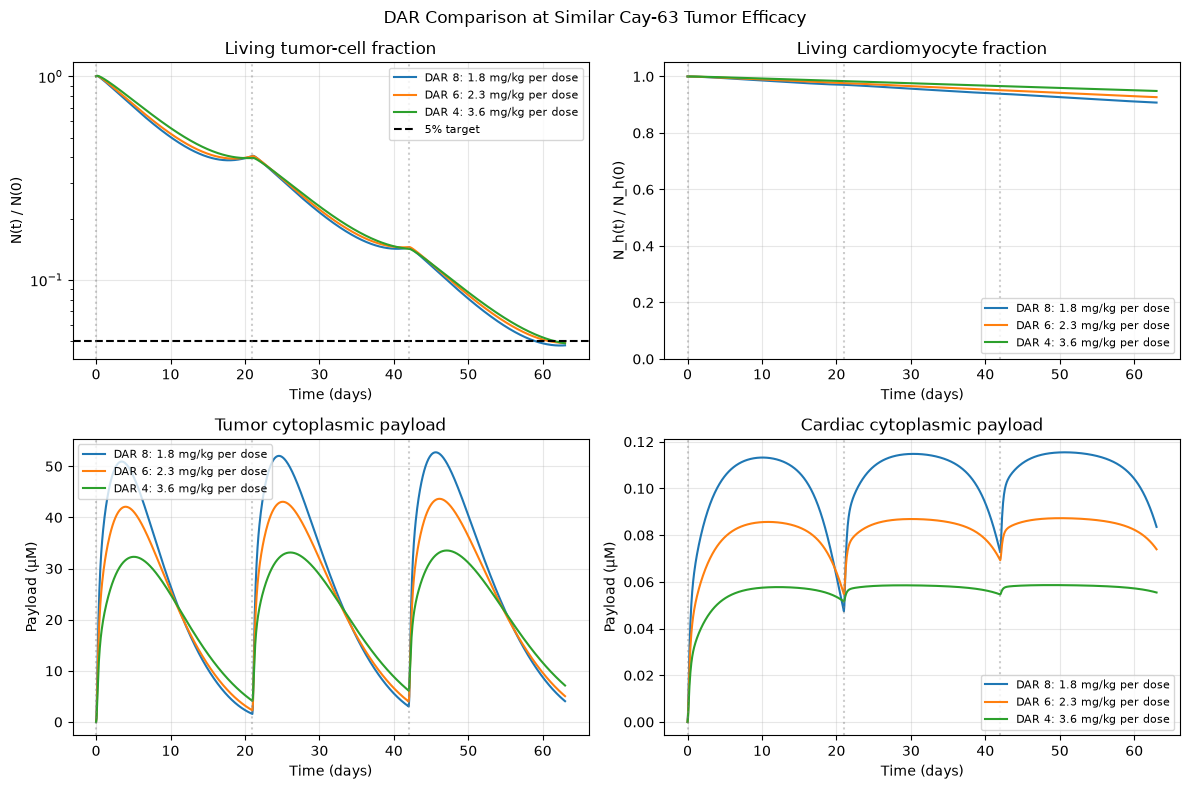

In [31]:
### Plotting Tumor and Cardiac Population and Cytoplasmic Payload Curves for Each DAR at the Selected Dose

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for X, (dose, result) in dar_results.items():
    dose, result = dar_results[X]
    days = result.in_days()
    label = f'DAR {X}: {dose:.1f} mg/kg per dose'

    tumor_fraction = result['N'] / initial_values_v2['N']
    heart_fraction = result['N_h'] / initial_values_v2['N_h']

    # Convert molecules/cell to intracellular concentration in µM
    tumor_payload_uM = (result['P_c'] / (N_A * cell_volume_L) * 1e6)
    heart_payload_uM = (result['P_c_h'] / (N_A * V_cell_h) * 1e6)

    axes[0, 0].plot(days, tumor_fraction, label=label)
    axes[0, 1].plot(days, heart_fraction, label=label)
    axes[1, 0].plot(days, tumor_payload_uM, label=label)
    axes[1, 1].plot(days, heart_payload_uM, label=label)

axes[0, 0].set_title('Living tumor-cell fraction')
axes[0, 0].set_ylabel('N(t) / N(0)')
axes[0, 0].set_yscale('log')
axes[0, 0].axhline(
    target_fraction_remaining,
    color='black', linestyle='--', label='5% target'
)

axes[0, 1].set_title('Living cardiomyocyte fraction')
axes[0, 1].set_ylabel('N_h(t) / N_h(0)')
axes[0, 1].set_ylim(0, 1.05)

axes[1, 0].set_title('Tumor cytoplasmic payload')
axes[1, 0].set_ylabel('Payload (µM)')

axes[1, 1].set_title('Cardiac cytoplasmic payload')
axes[1, 1].set_ylabel('Payload (µM)')

for ax in axes.flat:
    for day in dose_days:
        ax.axvline(day, color='gray', linestyle=':', alpha=0.4)
    ax.set_xlabel('Time (days)')
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)

fig.suptitle('DAR Comparison at Similar Cay-63 Tumor Efficacy')
plt.tight_layout()
plt.show()

In [33]:
### Do the selected dose regimens for each DAR meet the 5% tumor remaining target under varying cardiomyocyte initial cell counts?

heart_counts = {
    'Low': N_h_0 - N_h_uncertainty,
    'Baseline': N_h_0,
    'High': N_h_0 + N_h_uncertainty,
}

N_h_sensitivity_results = {}
N_h_sensitivity_rows = []

for X in (8, 6, 4):
    dose = dar_results[X][0]
    model_X = set_DAR(X)

    for scenario, heart_count in heart_counts.items():
        # Change only the initial cardiac population.
        scenario_initial = initial_values_v2.copy()
        scenario_initial['N_h'] = heart_count

        result = run_regimen(dose, model_X, scenario_initial)
        N_h_sensitivity_results[(X, scenario)] = result

        tumor_fraction = result['N'][-1] / scenario_initial['N']
        heart_loss = 100 * (1 - result['N_h'][-1] / scenario_initial['N_h'])

        N_h_sensitivity_rows.append({
            'DAR': X,
            'Scenario': scenario,
            'Initial N_h (billions)': heart_count / 1e9,
            'Dose (mg/kg)': dose,
            'Tumor remaining (%)': 100 * tumor_fraction,
            'Meets tumor target': tumor_fraction <= target_fraction_remaining,
            'Cardiomyocyte loss (%)': heart_loss,
            'Cardiac AUC (µM h)': result['AUC_P_c_h'][-1] * 1e6 / 60,
            'Blood AUC (µg h/mL)':
                result['AUC_P_b'][-1] * payload_MW * 1e3 / 60,
        })

N_h_sensitivity_table = pd.DataFrame(N_h_sensitivity_rows)
display(N_h_sensitivity_table.round(4))

,DAR,Scenario,Initial N_h (billions),Dose (mg/kg),Tumor remaining (%),Meets tumor target,Cardiomyocyte loss (%),Cardiac AUC (µM h),Blood AUC (µg h/mL)
0,8,Low,2.45,1.8,4.0393,True,9.4424,160.4044,0.5840
1,8,Baseline,3.20,1.8,4.7692,True,9.2420,156.8008,0.5672
2,8,High,3.95,1.8,5.7037,False,8.9817,152.1403,0.5516
3,6,Low,2.45,2.3,4.3384,True,7.4013,124.0539,0.5756
4,6,Baseline,3.20,2.3,4.9009,True,7.3230,122.6794,0.5619
5,6,High,3.95,2.3,5.5985,False,7.2133,120.7600,0.5487
6,4,Low,2.45,3.6,4.5756,True,5.1444,84.9826,0.6281
7,4,Baseline,3.20,3.6,4.8795,True,5.1331,84.7902,0.6182
8,4,High,3.95,3.6,5.2312,False,5.1185,84.5411,0.6084
